# Stock Market Time Series Analysis

## 1. Dataset Acquisition

We will download the Netflix Stock Price dataset from Kaggle.

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.arima.model import ARIMA
import warnings
import kagglehub
import os
warnings.filterwarnings('ignore')

# Download a completely public, open stock dataset (S&P 500) from Kaggle using kagglehub
path = kagglehub.dataset_download("camnugent/sandp500")

# Find the CSV file inside the downloaded directory
# We will use 'all_stocks_5yr.csv' which contains all data
csv_path = os.path.join(path, 'all_stocks_5yr.csv')

# Load dataset
full_df = pd.read_csv(csv_path)

# Filter for a single stock (e.g., Apple - AAPL) to perform time series analysis
df = full_df[full_df['Name'] == 'AAPL'].copy()

# Rename columns to match standard capitalization expected by the downstream code
df = df.rename(columns={
    'date': 'Date',
    'open': 'Open',
    'high': 'High',
    'low': 'Low',
    'close': 'Close',
    'volume': 'Volume'
})

print("Dataset successfully downloaded from Kaggle!")
display(df.head())

Dataset successfully downloaded from Kaggle!


,Date,Open,High,Low,Close,Volume,Name
1259,2013-02-08,67.7142,68.4014,66.8928,67.8542,158168416,AAPL
1260,2013-02-11,68.0714,69.2771,67.6071,68.5614,129029425,AAPL
1261,2013-02-12,68.5014,68.9114,66.8205,66.8428,151829363,AAPL
1262,2013-02-13,66.7442,67.6628,66.1742,66.7156,118721995,AAPL
1263,2013-02-14,66.3599,67.3771,66.2885,66.6556,88809154,AAPL


In [5]:
%pip install statsmodels kagglehub

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## 2. Dataset Exploration and Datetime Formatting

In [6]:
df.info()

# Convert Date column to datetime format
df['Date'] = pd.to_datetime(df['Date'])
df.set_index('Date', inplace=True)
df.sort_index(inplace=True)

display(df.head())

<class 'pandas.DataFrame'>
RangeIndex: 1259 entries, 1259 to 2517
Data columns (total 7 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Date    1259 non-null   str    
 1   Open    1259 non-null   float64
 2   High    1259 non-null   float64
 3   Low     1259 non-null   float64
 4   Close   1259 non-null   float64
 5   Volume  1259 non-null   int64  
 6   Name    1259 non-null   str    
dtypes: float64(4), int64(1), str(2)
memory usage: 86.5 KB


,Open,High,Low,Close,Volume,Name
Date,,,,,,
2013-02-08,67.7142,68.4014,66.8928,67.8542,158168416,AAPL
2013-02-11,68.0714,69.2771,67.6071,68.5614,129029425,AAPL
2013-02-12,68.5014,68.9114,66.8205,66.8428,151829363,AAPL
2013-02-13,66.7442,67.6628,66.1742,66.7156,118721995,AAPL
2013-02-14,66.3599,67.3771,66.2885,66.6556,88809154,AAPL


## 3. Historical Stock Price Trends

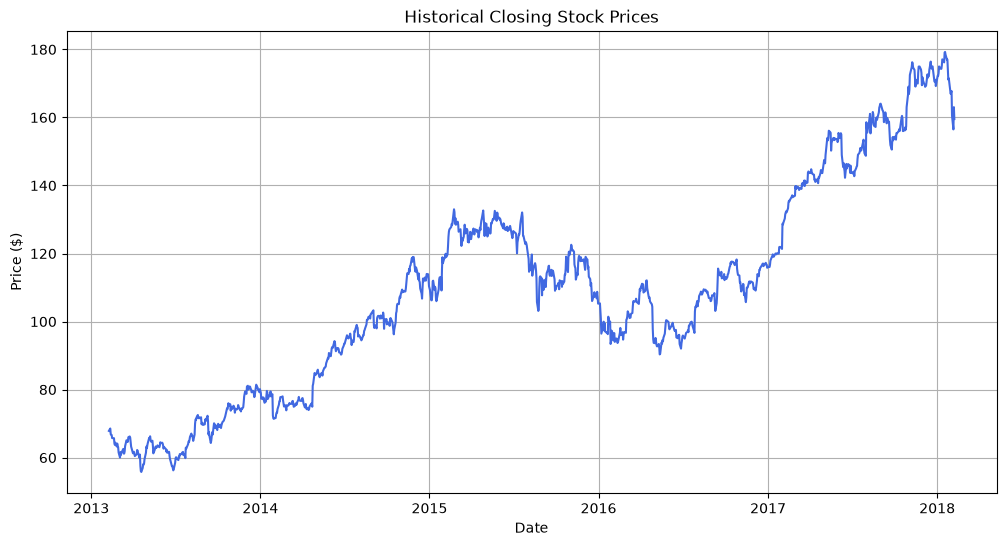

In [7]:
plt.figure(figsize=(12, 6))
plt.plot(df['Close'], color='royalblue')
plt.title('Historical Closing Stock Prices')
plt.xlabel('Date')
plt.ylabel('Price ($)')
plt.grid(True)
plt.show()

## 4. Moving Averages

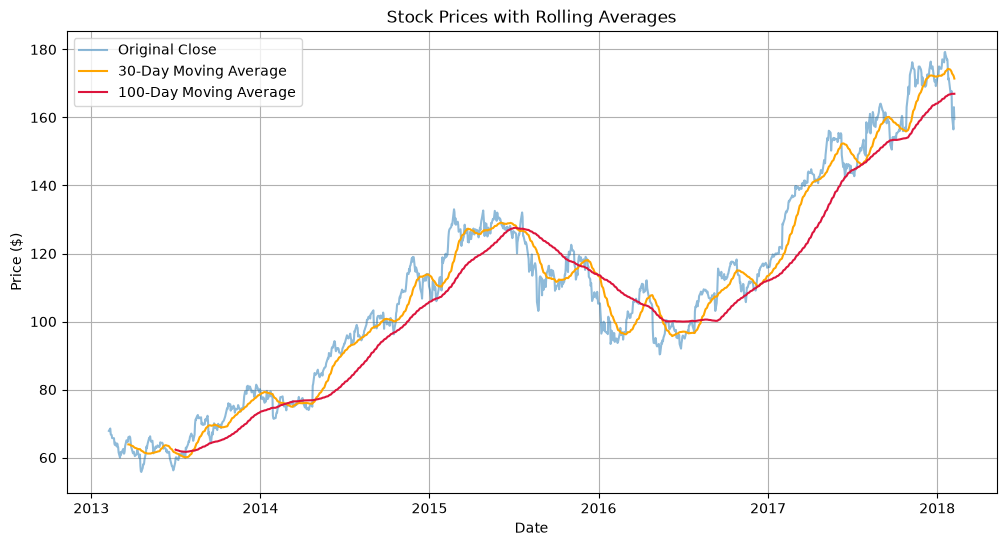

In [8]:
df['MA30'] = df['Close'].rolling(window=30).mean()
df['MA100'] = df['Close'].rolling(window=100).mean()

plt.figure(figsize=(12, 6))
plt.plot(df['Close'], label='Original Close', alpha=0.5)
plt.plot(df['MA30'], label='30-Day Moving Average', color='orange')
plt.plot(df['MA100'], label='100-Day Moving Average', color='crimson')
plt.title('Stock Prices with Rolling Averages')
plt.xlabel('Date')
plt.ylabel('Price ($)')
plt.legend()
plt.grid(True)
plt.show()

## 5. Seasonality Analysis

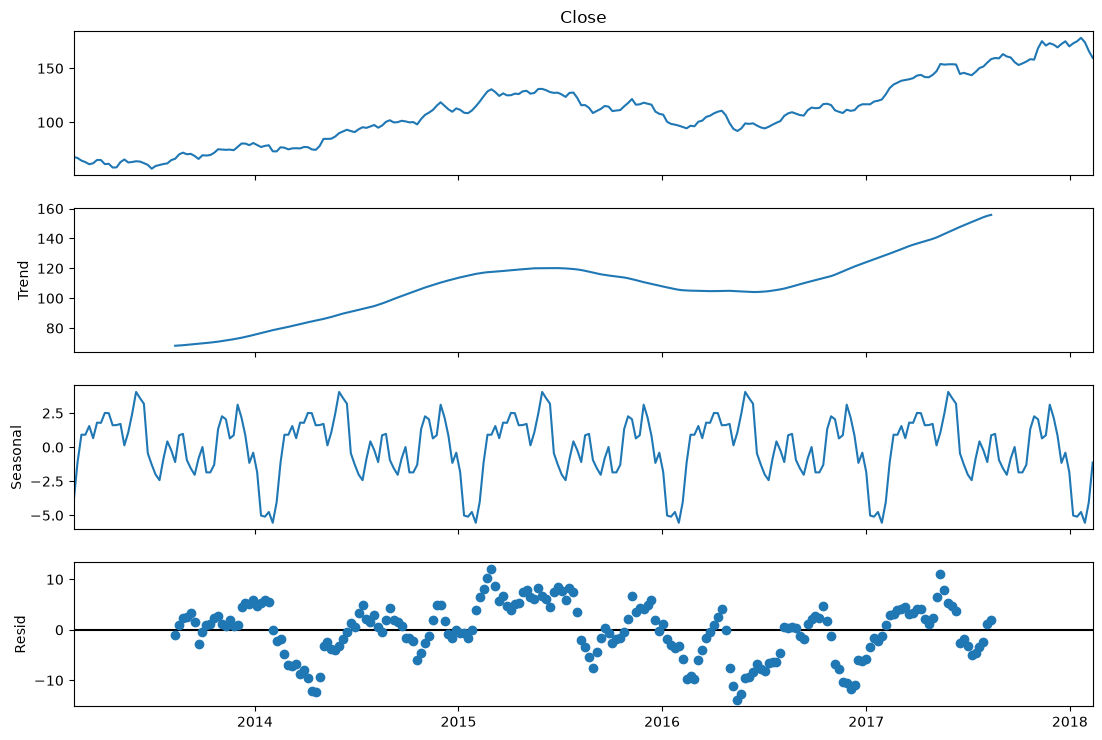

In [9]:
# Decompose closing price to observe trend, seasonality, and residuals
# Resampling to weekly to reduce noise in decomposition
weekly_close = df['Close'].resample('W').mean().ffill()

decomposition = seasonal_decompose(weekly_close, model='additive', period=52)

fig = decomposition.plot()
fig.set_size_inches(12, 8)
plt.show()

## 6. Correlation Analysis

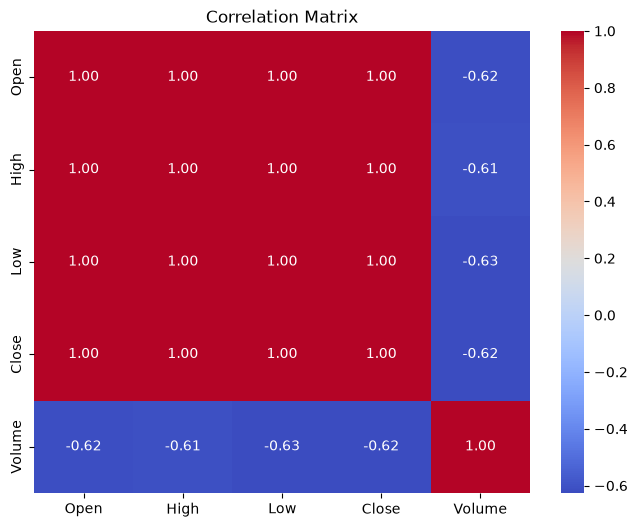

In [10]:
correlation_matrix = df[['Open', 'High', 'Low', 'Close', 'Volume']].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix')
plt.show()

## 7. ARIMA Forecasting

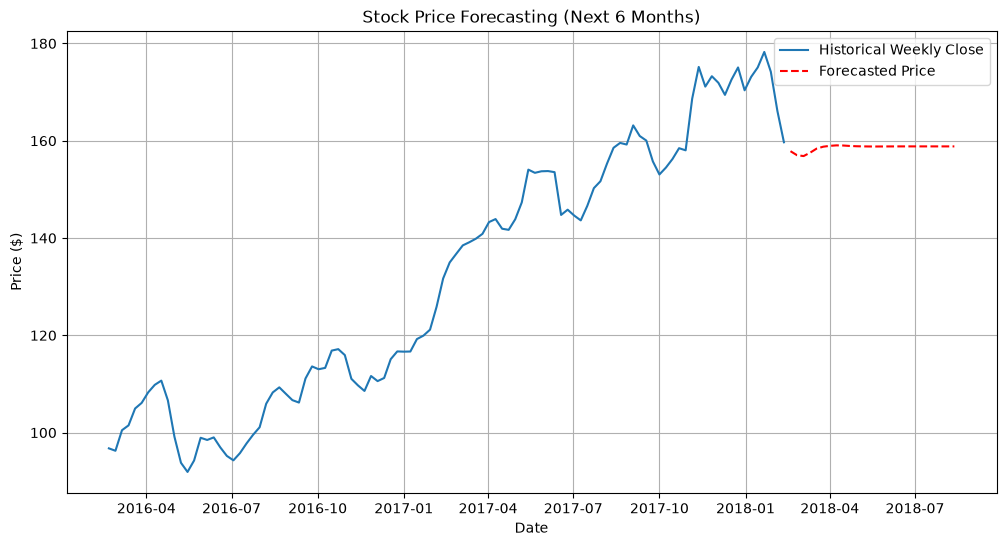

In [11]:
# We will train the model on weekly averaged data for smoother forecasting
model = ARIMA(weekly_close, order=(5, 1, 0))
results = model.fit()

forecast_steps = 26
forecast = results.get_forecast(steps=forecast_steps)
forecast_index = pd.date_range(start=weekly_close.index[-1], periods=forecast_steps + 1, freq='W')[1:]
forecast_series = pd.Series(forecast.predicted_mean.values, index=forecast_index)

plt.figure(figsize=(12, 6))
plt.plot(weekly_close[-104:], label='Historical Weekly Close')
plt.plot(forecast_series, label='Forecasted Price', color='red', linestyle='--')
plt.title('Stock Price Forecasting (Next 6 Months)')
plt.xlabel('Date')
plt.ylabel('Price ($)')
plt.legend()
plt.grid(True)
plt.show()